# Galaxy Evidence Lab â€” two real pilot galaxies

Download this notebook and galaxy-example.zip into one folder, extract the ZIP, then run all cells. Offline review needs numpy and matplotlib. No archive downloads by default. This notebook shows **conditional measurements**, not validated spectra or redshifts.

## End-to-end workflow
1. Identify the object and inspect catalogue entries in high-resolution images.
2. Select native SPHEREx exposures by coverage/date/wavelength metadata; seek up to 3 per channel, record shortages.
3. Apply explicit release calibration, pixel masks and per-exposure coordinate mapping.
4. Render target and neighbours with their shapes and local ePSFs; fit brightnesses/sky in native pixels.
5. Preserve per-exposure response kernels, uncertainty and flags.
6. Inspect residuals and predict held-out exposures through their responses; run known-answer injections.
7. Assemble a joint spectrum with validated systematic uncertainty.
8. Only if gates support it: calculate P(z), retain alternate modes, compare with held-out spectroscopy, derive named cosmological distances.

Steps1â€“5 have pilot products. Steps6â€“8 remain incomplete; notebook execution does not certify those gates.

## Before running: environment and integrity

Use Python3.10+ with **NumPy2.0+**, matplotlib, Pillow and Jupyter. Optional native fitting additionally needs the science repository's astropy/scipy/photutils/requests/pyvo dependencies. No installation or archive requests run automatically. Run from the folder containing the extracted `galaxy-example` directory.

The next cell checks the small evidence bundle and records local software versions. This verifies files, not astrophysical correctness.

In [1]:
import sys,hashlib,importlib.metadata,platform
from pathlib import Path
import json
DATA=Path('galaxy-example')
assert DATA.is_dir(), 'Extract galaxy-example.zip next to this notebook first.'
assert tuple(int(v) for v in __import__('numpy').__version__.split('.')[:2]) >= (2,0), 'Use NumPy2.0+ for np.trapezoid.'
expected=json.loads((DATA/'bundle_manifest.json').read_text(encoding="utf8"))
for name,digest in expected['files'].items():
    assert hashlib.sha256((DATA/name).read_bytes()).hexdigest()==digest, f'Bundle file changed: {name}'
runtime={'python':sys.version,'platform':platform.platform()}
for name in ['numpy','matplotlib','Pillow','nbformat']:
    try: runtime[name]=importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: runtime[name]='not installed'
print(runtime)
print('Evidence-file hashes verified; scientific gates remain independent.')

{'python': '3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'Pillow': '13.0.0', 'nbformat': '5.11.1'}
Evidence-file hashes verified; scientific gates remain independent.


In [2]:
from pathlib import Path
import json,csv
import numpy as np
import matplotlib.pyplot as plt
DATA=Path('galaxy-example')
rows=list(csv.DictReader((DATA/'measurements.csv').open()))
provenance=json.loads((DATA/'provenance.json').read_text())
for key,value in provenance.items(): print(key,':',value)
print('Saved measurements:',len(rows))

scope : Two galaxy candidates; up to three observations per nominal channel; no accepted redshift.
sky_positions : Legacy DR9 catalogue ra/dec, mapped separately through each SPHEREx exposure WCS. Galaxy positions fixed; Legacy PSF-source proper motion propagated when finite pmra/pmdec and ref_epoch>1990.
galaxy_shapes : Legacy DR9 Tractor model type, shape_r, shape_e1, shape_e2, Sersic index; ellipse projected using local WCS. Optical prior is not assumed to be exact NIR morphology.
alternate_shapes : Euclid and HEROES/HSC investigated, not adopted as blanket replacements. Current measurements use Legacy baseline shapes.
gaia : Gaia was investigated for identity/position diagnostics; these native fits do not substitute Gaia brightnesses or universally replace Legacy positions.
brightness : Fitted from SPHEREx native IMAGE/VARIANCE pixels, not copied from Legacy optical or Gaia brightness.
psf : Each source uses its local SPHEREx ePSF; extended profiles convolved with that ePSF. ePSF i

## Actual adopted target shapes and positions
Both pilot targets use Legacy REX round-exponential optical priors, not resolved spiral-arm models. Shape radius is in arcseconds. A ref_epoch of0 is not an actual observing epoch and is not used for stellar proper motion; see optical MJD ranges. Gaia positions/brightnesses and Euclid profiles were not universally substituted.

In [3]:
for target_input in json.loads((DATA/'adopted_inputs.json').read_text()):
    print(target_input)

{'object_id': 'LS9_9011_636281_2835', 'catalogue': 'Legacy DR9', 'shape_status': 'optical prior adopted, not proven exact in NIR', 'ra': 268.54442471663674, 'dec': 67.36513874766023, 'type': 'REX', 'shape_r': 1.272283, 'shape_e1': 0.0, 'shape_e2': 0.0, 'sersic': 1.0, 'ref_epoch': 0.0, 'pmra': 0.0, 'pmdec': 0.0, 'maskbits': 0, 'fitbits': 0, 'mjd_min': 58027.195150460735, 'mjd_max': 58286.37289316583}
{'object_id': 'LS9_9011_633415_2993', 'catalogue': 'Legacy DR9', 'shape_status': 'optical prior adopted, not proven exact in NIR', 'ra': 269.5723292210919, 'dec': 66.00480288970027, 'type': 'REX', 'shape_r': 0.896745, 'shape_e1': 0.0, 'shape_e2': 0.0, 'sersic': 1.0, 'ref_epoch': 0.0, 'pmra': 0.0, 'pmdec': 0.0, 'maskbits': 0, 'fitbits': 0, 'mjd_min': 57908.45903935074, 'mjd_max': 58311.30259398744}


## Actual coverage: what was measured?

The first galaxy has102 nominal channels and the second 95. Not every channel has three distinct observations. A channel with an unflagged conditional fit is not automatically science-usable. SOURCE is not an automatic bad-pixel reason, and signed weak/negative fluxes are retained.

In [4]:
from collections import Counter
for oid in sorted({r['object_id'] for r in rows}):
    a=[r for r in rows if r['object_id']==oid]
    by_channel=Counter(r['nominal_channel'] for r in a)
    print(oid,dict(measurements=len(a),nominal_channels=len(by_channel),exposures_per_channel=dict(Counter(by_channel.values())),flagged=sum(bool(r['flags']) for r in a),nonpositive_flux=sum(float(r['flux_Jy'])<=0 for r in a)))

LS9_9011_633415_2993 {'measurements': 255, 'nominal_channels': 95, 'exposures_per_channel': {3: 76, 1: 11, 2: 8}, 'flagged': 8, 'nonpositive_flux': 25}
LS9_9011_636281_2835 {'measurements': 306, 'nominal_channels': 102, 'exposures_per_channel': {3: 102}, 'flagged': 11, 'nonpositive_flux': 2}


## Inspect both scenes
Catalogue entries are retained. These optical coadds are not a single epoch or infrared truth. The native measurement models use the provenance above.

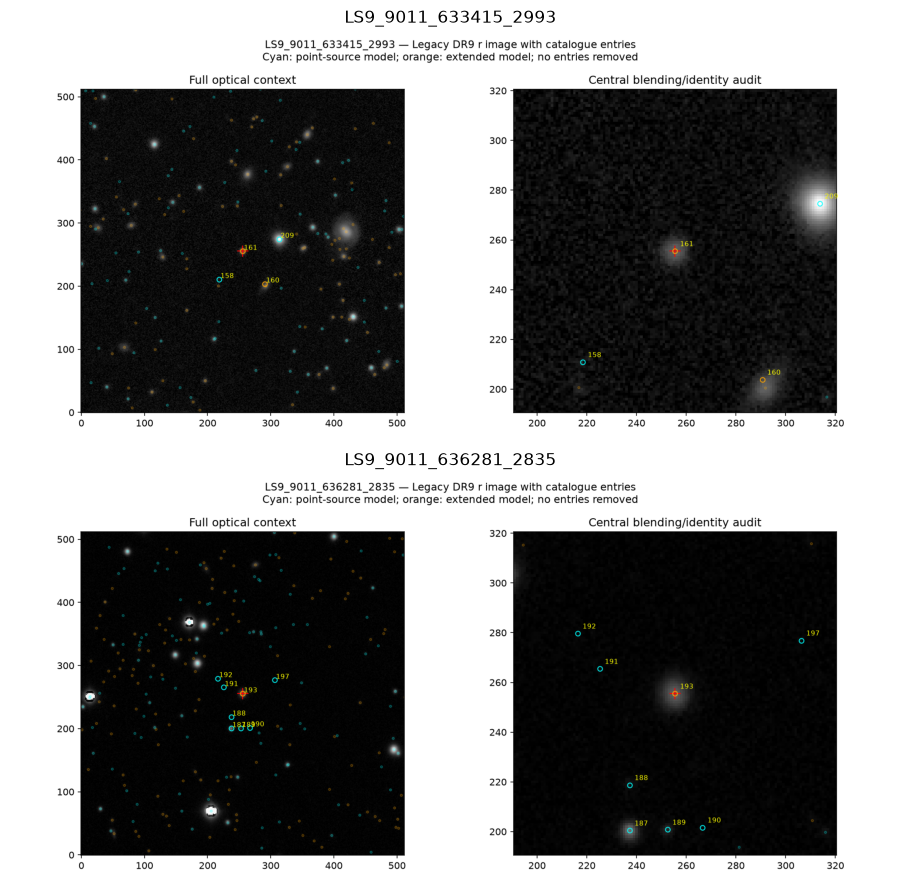

In [5]:
ids=sorted({r['object_id'] for r in rows})
fig,axes=plt.subplots(len(ids),1,figsize=(13,9))
for ax,oid in zip(axes,ids):
    ax.imshow(plt.imread(DATA/f'{oid}_scene.png')); ax.axis('off'); ax.set_title(oid)
plt.tight_layout(); plt.show()

## Individual exposure measurements
Each point is a separate native fit with its own response. No blind channel averaging. Red circles retain existing fit-quality flags; they do not identify the cause of a failure.

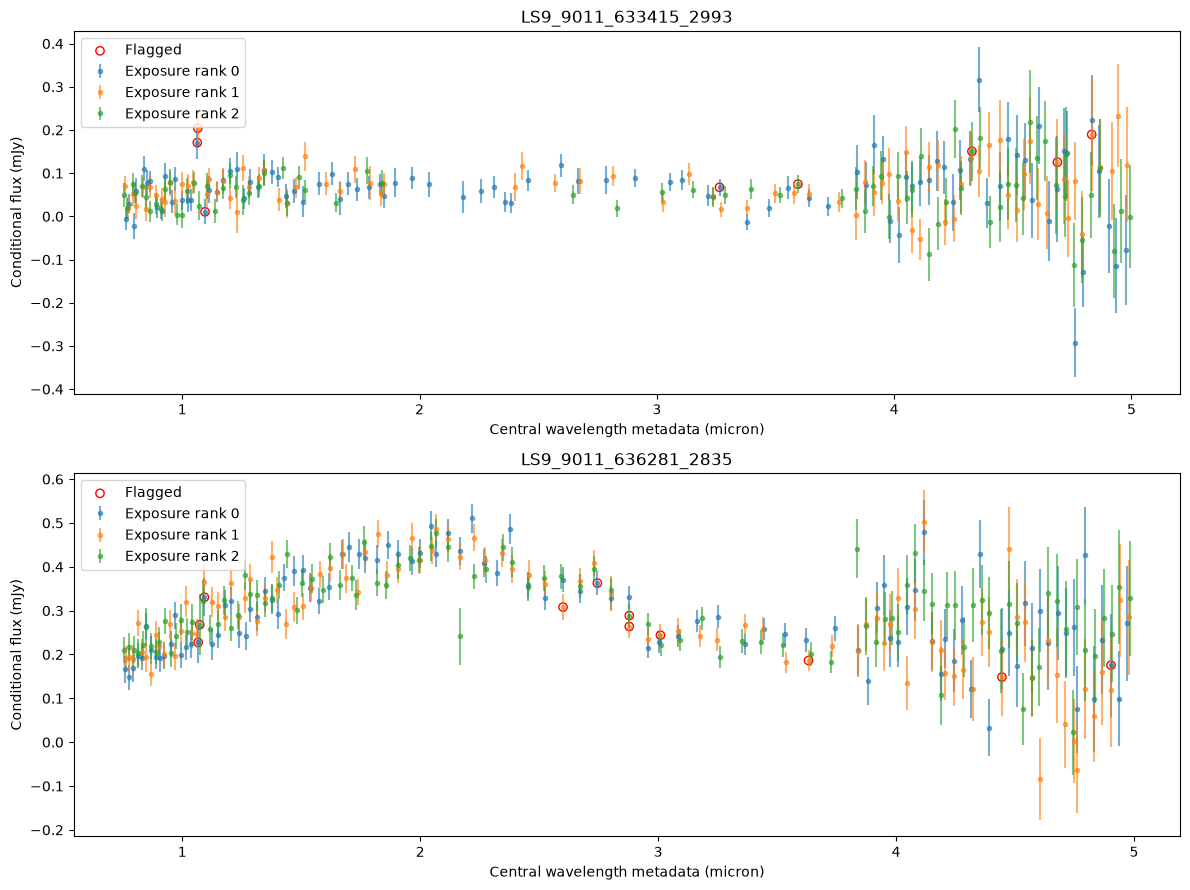

In [6]:
fig,axes=plt.subplots(2,1,figsize=(12,9))
for ax,oid in zip(axes,ids):
    for rank in [0,1,2]:
        a=[r for r in rows if r['object_id']==oid and int(r['rank'])==rank]
        ax.errorbar([float(r['wavelength_um']) for r in a],[1000*float(r['flux_Jy']) for r in a],yerr=[1000*float(r['conditional_error_Jy']) for r in a],fmt='.',alpha=.6,label=f'Exposure rank {rank}')
    bad=[r for r in rows if r['object_id']==oid and r['flags']]
    ax.scatter([float(r['wavelength_um']) for r in bad],[1000*float(r['flux_Jy']) for r in bad],facecolors='none',edgecolors='red',label='Flagged')
    ax.set(title=oid,xlabel='Central wavelength metadata (micron)',ylabel='Conditional flux (mJy)');ax.legend()
plt.tight_layout();plt.show()

## Reproduce the conditional precision calculation
For a fixed **assumed** flat Fnu spectrum and independent supplied noise, response-integrated Fisher information gives the potential amplitude-error reduction. This is not empirical accuracy or a fitted galaxy spectrum. Keep full kernels: changing wavelengths is not just repeating the same flux.

In [7]:
operators=np.load(DATA/'response_operators.npz')
lookup={str(k):i for i,k in enumerate(operators['job_ids'])}
# Decompress arrays once, not for every channel measurement.
wave_grid=operators['wave_um']; kernel_grid=operators['conditioned_kernel']
flat_response=np.trapezoid(kernel_grid,wave_grid,axis=1)
gains={}
for oid in ids:
    ratios=[]
    for ch in sorted({r['nominal_channel'] for r in rows if r['object_id']==oid}):
        a=[r for r in rows if r['object_id']==oid and r['nominal_channel']==ch]
        baseline=next(r for r in a if int(r['rank'])==0)
        response=lambda r: flat_response[lookup[r['job_id']]]
        information=sum((response(r)/float(r['conditional_error_Jy']))**2 for r in a)
        baseline_error=float(baseline['conditional_error_Jy'])/abs(response(baseline))
        ratios.append((1/np.sqrt(information))/baseline_error)
    gains[oid]=100*(1-np.median(ratios))
print('Median conditional error reduction (%):',gains)
print('Not validated absolute accuracy. See information_comparison.json for flag-stratified slopes and assumptions.')

Median conditional error reduction (%): {'LS9_9011_633415_2993': np.float64(41.58532115042783), 'LS9_9011_636281_2835': np.float64(41.88039890285863)}
Not validated absolute accuracy. See information_comparison.json for flag-stratified slopes and assumptions.


## Keep flagged and filtered precision forecasts separate

The earlier flat-spectrum calculation includes all saved fits. Here the saved comparison also shows the existing-quality-filtered stratum. Excluding the baseline makes that channel's paired baseline comparison unavailable. Different smooth assumed slopes are sensitivity checks, not fitted galaxy templates. These are information forecasts: no true flux, calibrated coverage or redshift accuracy is measured.

In [8]:
comparison=json.loads((DATA/'information_comparison.json').read_text(encoding="utf8"))
for group in comparison['groups']:
    if group['powerlaw_slope_Fnu']==0:
        print(group['object_id'],group['sample'], 'channels',group['fully_extracted_comparable_channels'],'median conditional error reduction (%)',round(group['median_conditional_error_reduction_percent'],2))

LS9_9011_633415_2993 all_saved channels 95 median conditional error reduction (%) 41.59
LS9_9011_633415_2993 without_existing_chi2_flags channels 92 median conditional error reduction (%) 40.29
LS9_9011_636281_2835 all_saved channels 102 median conditional error reduction (%) 41.88
LS9_9011_636281_2835 without_existing_chi2_flags channels 98 median conditional error reduction (%) 41.68


## Residual evidence
Two channel 58 repeats have large residuals dominated by individual pixels. Neither automatic pixel removal nor a catalogue correction is justified yet. The baseline is cleaner, but is not external brightness truth.

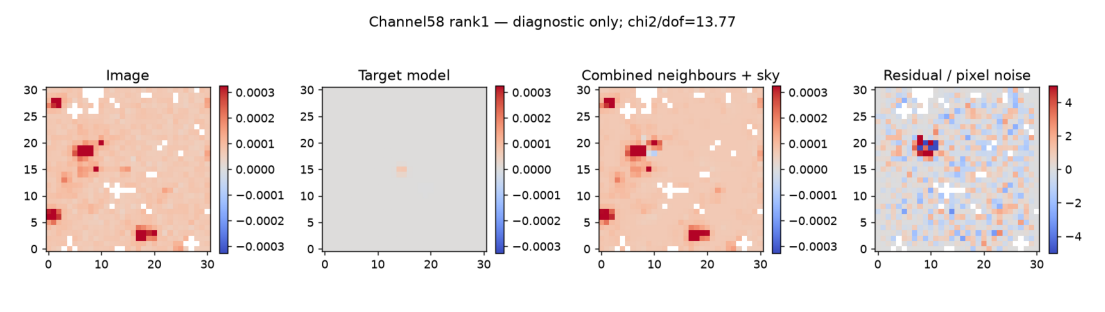

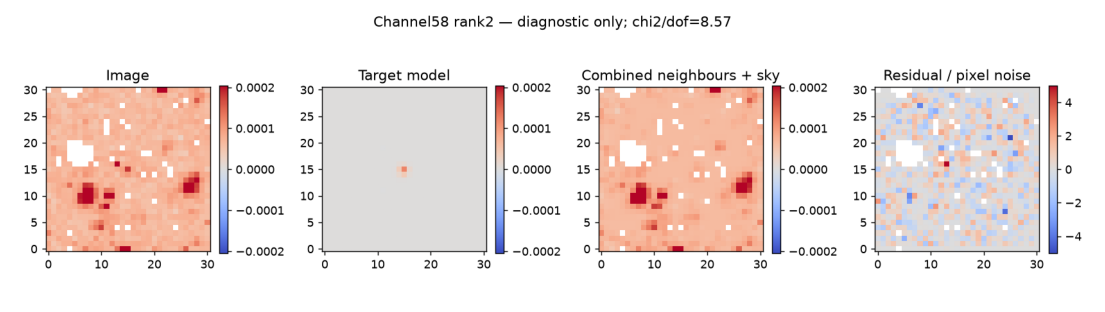

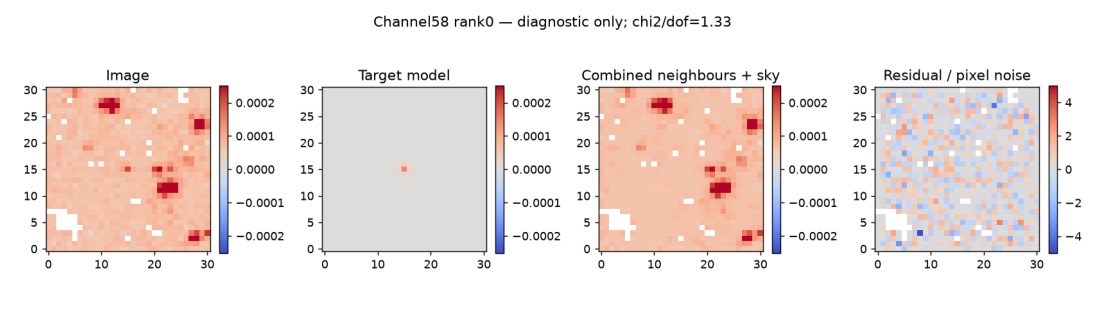

Redshift status: not inferred â€” measurement/systematic validation gates remain open.


In [9]:
for file in sorted(DATA.glob('*.png')):
    if file.name.endswith('_scene.png'): continue
    fig,ax=plt.subplots(figsize=(14,4));ax.imshow(plt.imread(file));ax.axis('off');plt.show()
print('Redshift status: not inferred â€” measurement/systematic validation gates remain open.')

## Held-out exposure predictions — limited model check

For each channel, predict each eligible exposure using the other unflagged repeats. Use three **predeclared** smooth Fnu power-law slopes (-2,0,+2), integrated separately through each actual response kernel. Do not select whichever slope makes a case pass. Fit a single amplitude, retain signed fluxes and propagate conditional training plus test noise.

This tests observed repeat consistency **under those restricted spectral assumptions**. Emission/absorption features can invalidate a smooth assumption. Comparisons share observations and are correlated; totals are not independent trials. Passing this check cannot rule out shared morphology/calibration bias. No error multiplier is fitted and no redshift/reference flux is used.

In [10]:
import csv
predictions=[]
for oid in ids:
    channels=sorted({r['nominal_channel'] for r in rows if r['object_id']==oid},key=int)
    for ch in channels:
        records=[r for r in rows if r['object_id']==oid and r['nominal_channel']==ch and not r['flags']]
        if len(records)<2: continue
        centre=float(__import__('numpy').median([float(r['wavelength_um']) for r in records]))
        for slope in [-2,0,2]:
            responses={}
            for r in records:
                i=lookup[r['job_id']]
                responses[r['job_id']]=float(np.trapezoid(kernel_grid[i]*(wave_grid[i]/centre)**slope,wave_grid[i]))
            for test in records:
                train=[r for r in records if r['job_id']!=test['job_id']]
                information=sum((responses[r['job_id']]/float(r['conditional_error_Jy']))**2 for r in train)
                if information<=0: continue
                amplitude=sum(responses[r['job_id']]*float(r['flux_Jy'])/float(r['conditional_error_Jy'])**2 for r in train)/information
                rt=responses[test['job_id']];predicted=amplitude*rt
                predictive_sigma=np.sqrt(float(test['conditional_error_Jy'])**2+rt**2/information)
                predictions.append(dict(object_id=oid,nominal_channel=ch,slope=slope,test_job=test['job_id'],training_measurements=len(train),predicted_Jy=predicted,observed_Jy=float(test['flux_Jy']),conditional_predictive_sigma_Jy=float(predictive_sigma),pull=(float(test['flux_Jy'])-predicted)/predictive_sigma))
for oid in ids:
    for slope in [-2,0,2]:
        a=[r for r in predictions if r['object_id']==oid and r['slope']==slope]
        pulls=np.array([r['pull'] for r in a])
        print(oid,'assumed slope',slope,'correlated predictions',len(a),'median pull',round(float(np.median(pulls)),3),'RMS',round(float(np.sqrt(np.mean(pulls**2))),3),'abs pull >3',int(np.sum(abs(pulls)>3)))
with Path('galaxy-heldout-predictions.csv').open('w',newline='') as h:
    writer=csv.DictWriter(h,fieldnames=list(predictions[0]));writer.writeheader();writer.writerows(predictions)
print('Saved galaxy-heldout-predictions.csv; this is not a brightness-accuracy score.')

LS9_9011_633415_2993 assumed slope -2 correlated predictions 234 median pull 0.02 RMS 1.049 abs pull >3 0
LS9_9011_633415_2993 assumed slope 0 correlated predictions 234 median pull 0.012 RMS 1.048 abs pull >3 0
LS9_9011_633415_2993 assumed slope 2 correlated predictions 234 median pull 0.005 RMS 1.048 abs pull >3 0
LS9_9011_636281_2835 assumed slope -2 correlated predictions 293 median pull -0.001 RMS 1.16 abs pull >3 1
LS9_9011_636281_2835 assumed slope 0 correlated predictions 293 median pull 0.001 RMS 1.159 abs pull >3 1
LS9_9011_636281_2835 assumed slope 2 correlated predictions 293 median pull 0.002 RMS 1.159 abs pull >3 2
Saved galaxy-heldout-predictions.csv; this is not a brightness-accuracy score.


## Quantify the residual-pixel concern

Residual PNGs are clipped for display and can hide very large values. The following tables retain the measured peak significance, positional association and post-hoc deletion sensitivity. Nearest catalogue association does not establish cause. The experiment does not justify deleting astrophysical pixels or adopting a replacement brightness.

In [11]:
localization=json.loads((DATA/'residual_source_localization.json').read_text(encoding="utf8"))
for r in localization['rows']:
    peak=r['peaks'][0]
    print('rank',r['rank'],'largest-pixel fraction of residual power',round(r['largest_pixel_fraction_of_residual_power'],3),'peak conditional noise units',round(peak['normalized_residual'],2),'distance from target (pixels)',round(peak['distance_to_target_pixels'],2),'nearest entry',peak['nearest_catalogue_id'])
for r in json.loads((DATA/'pixel_sensitivity.json').read_text(encoding="utf8")):
    print('rank',r['job']['rank'],'peak flags',r['peak_flags'],'post-hoc flux change / original conditional error',round(r['diagnostic_flux_change_in_original_sigma'],3),'adopted',r['adopted'])

rank 1 largest-pixel fraction of residual power 0.797 peak conditional noise units 79.84 distance from target (pixels) 6.93 nearest entry LS9_9011_636837_1238
rank 2 largest-pixel fraction of residual power 0.866 peak conditional noise units 65.14 distance from target (pixels) 2.21 nearest entry LS9_9011_636281_2835
rank 0 largest-pixel fraction of residual power 0.08 peak conditional noise units -7.96 distance from target (pixels) 13.97 nearest entry LS9_9011_636837_813
rank 1 peak flags ['SOURCE'] post-hoc flux change / original conditional error 0.091 adopted False
rank 2 peak flags ['SOURCE'] post-hoc flux change / original conditional error -0.057 adopted False
rank 0 peak flags [] post-hoc flux change / original conditional error -0.066 adopted False


## Decision checkpoint before redshift

**Complete:** native conditional measurement extraction; per-exposure kernels; internal normalization; limited optical identity audit; initial repeat-information comparison.

**Partial:** observed held-out consistency under restricted smooth spectral models; targeted flagged residual inspection. The optical prior is not proven correct in infrared.

**Not passed:** independent off-model injection recovery/uncertainty calibration for the adopted joint-spectrum method; validated morphology/PSF/background/calibration systematic covariance; accepted response-integrated spectrum; real-galaxy P(z) validation.

Therefore no cosmological distance, recession velocity or3D coordinate is produced here. Two secure spectroscopy references are reserved for later independent comparison; they are not fitting inputs and cannot establish population accuracy. Write 'unavailable' instead of substituting catalogue redshifts.

These checks must be repeated for another galaxy: this review notebook is not an automatically validated all-sky pipeline.

## Use this workflow for another galaxy

**A new coordinate alone is not enough to rerun the science fit.** First provide the inputs below. Do not rename the example object and reuse its fluxes.

1. Clone the science repository when published. Install its documented astronomy dependencies in a separate environment; record versions. The web bundle does not contain the 90 GB originals or complete calibration references.
2. The current optional fitter requires compatible **full-detector native SPHEREx exposures** with IMAGE, VARIANCE, FLAGS and delivered ePSFs. Official tutorial cutouts are useful for viewing but cannot be substituted directly: cutout detector offsets, calibration-map slicing and ePSF coordinates need an adapter that is not implemented here. Large/edge targets need a larger valid stamp; this 31×31 pilot is not universal.
3. Obtain a LegacyDR9 catalogue covering the entire target+neighbour field, with legacy_object_id,ra,dec,type,shape_r,shape_e1,shape_e2,sersic,pmra,pmdec,ref_epoch,maskbits,fitbits. If coverage/profile information is missing, supply a justified alternate catalogue adapter; do not silently assume point sources.
4. Supply the applicable QR3 calibration maps and QR2-to-QR3 gain references, plus ePSF reference files. Verify their release conventions.
5. Build a selected-exposures JSON list with file,release,obs_id,detector,mjd_start. Inspect actual target-position wavelength/bandwidth and valid coverage first; select distinct observations, up to 3 per nominal channel. Our NEP job generator is specific to its existing inventory and MUST NOT be used unchanged for a new coordinate.
6. Run the optional native-fit cell below with explicit paths. It reuses the existing scientific modules and checkpoints each exposure, but does not generate a final response-integrated spectrum or validate errors. Construct per-exposure kernels with the same documented response protocol before joint spectral fitting.
7. Repeat scene identity, residual, held-out prediction and injection checks. Define decisions before examining known redshifts. Keep unsuitable cases flagged.
8. If supported, use the released response-integrated redshift engine after its tests pass. Reserve independent spectroscopy for validation. Report unavailable distance instead of guessing.

The following is opt-in and intended for a checked-out science workspace, not an arbitrary hosted notebook filesystem.

The downloadable helper checks target identity, stamp bounds and input fingerprints. It still uses the existing scientific model and has not been demonstrated on a new galaxy. Put `galaxy_native_runner.py` next to the notebook. Supply a calibration manifest with `files: [{path, sha256}, ...]` for every adopted reference; relative paths resolve against that manifest. Keep runs small and serial until memory/runtime is benchmarked.

The downloadable helper checks target identity, stamp bounds and input fingerprints. It still uses the existing scientific model and has not been demonstrated on a new galaxy. Put `galaxy_native_runner.py` next to the notebook. Supply a calibration manifest with `files: [{path, sha256}, ...]` for every adopted reference; relative paths resolve against that manifest. Keep runs small and serial until memory/runtime is benchmarked.

In [12]:
RUN_NATIVE=False
CONFIG={
    'science_repo':'/path/to/science-repository',
    'data_root':'/path/to/data/root-with-science_calibrations',
    'catalogue':'/path/to/field_morphology_reference.fits',
    'exposures':'/path/to/selected_full_native_exposures.json',
    'epsf_calibration':'/path/to/epsf/calibration',
    'calibration_manifest':'/path/to/calibration-provenance.json',
    'output':'new-galaxy-native-results',
    'target':{'object_id':'YOUR_CATALOGUE_ID','ra':0.0,'dec':0.0}}
if RUN_NATIVE:
    import importlib.util
    helper=Path('galaxy_native_runner.py')
    assert helper.exists(), 'Download galaxy_native_runner.py beside this notebook.'
    spec=importlib.util.spec_from_file_location('galaxy_native_runner',helper)
    module=importlib.util.module_from_spec(spec);spec.loader.exec_module(module)
    print(module.run_native_review(CONFIG))
    print('Conditional native fits only. New-target validation and response integration still required.')
else:
    print('New-target fitting disabled. Review the documented prerequisites before enabling.')


New-target fitting disabled. Review the documented prerequisites before enabling.


## Credits and attribution

Data: NASA SPHEREx/Science Data Center and NASA/IPAC IRSA. [SPHEREx](https://spherex.caltech.edu/), [IRSA](https://irsa.ipac.caltech.edu/), [official cutout tutorial](https://caltech-ipac.github.io/irsa-tutorials/spherex-cutouts/).

Adopted galaxy positions/shapes and optical cutouts: [Legacy DR9](https://www.legacysurvey.org/dr9/) using Tractor catalogue geometry conventions; see [survey acknowledgements](https://www.legacysurvey.org/acknowledgment/). Gaia supplies optional overlays/earlier diagnostics, not galaxy brightness. Euclid/HSC were investigated, not universally adopted.

Software includes Python, NumPy, SciPy, Astropy, Photutils, Matplotlib, Pillow and Jupyter, under their respective licenses. OpenAI Codex assisted development. This independent Space Apps project is not NASA/IRSA-certified. Original observation IDs and processing provenance remain attached to the evidence. Full project credits are linked from the viewer.